# 01 · Data and point-in-time ASX 500 universe

Course project: *Statistical Arbitrage* (The Wall Street Quants). This notebook builds the data the strategy research in `02_channel_breakout_research.ipynb` runs on.

1. Download daily OHLCV for every ASX-listed company, plus benchmarks (Yahoo Finance).
2. Inspect raw data quality.
3. Clean returns: remove broken adjustment factors, bad prints and stale quotes.
4. Build a **point-in-time ASX 500**: the top 500 ordinary shares by traded value, rebuilt every month end.
5. Save everything to `data/clean.pkl`.

**Why we rebuild the universe.** There is no free historical list of ASX 500 members. Using today's members for 2006 would be look-ahead bias, because we would only trade stocks we already know grew big. Instead the universe is rebuilt at each month end from information available at that date.

In [1]:
import io
import time
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import requests
import yfinance as yf

pd.set_option("display.width", 200)
DATA = Path("data")
DATA.mkdir(exist_ok=True)

START = "2005-01-01"
BENCHMARKS = ["^AXJO", "^AORD"]   # ASX 200, All Ordinaries
N_UNIVERSE = 500
MIN_PRICE = 0.10                   # raw (unadjusted) close, A$
MIN_HISTORY = 252                  # trading days of price history before a stock is eligible
SPIKE = np.log(1.5)                # a one-day log move bigger than this (+50% / -33%) is "large"

## 1. Download

The ASX publishes its current company list as a CSV (code, name, GICS industry group). Every code gets `.AX` appended for Yahoo and is downloaded in batches of 100. Both the list and the price panel are cached in `data/`, so a re-run skips the ~10-minute download.

**Survivorship limitation:** this is *today's* listing, so companies that delisted before 2026 (takeovers, failures) are missing. The README discusses how that biases each side of the book.

In [2]:
def listed_companies() -> pd.DataFrame:
    path = DATA / "asx_listed.csv"
    if not path.exists():
        r = requests.get("https://www.asx.com.au/asx/research/ASXListedCompanies.csv",
                         headers={"User-Agent": "Mozilla/5.0"}, timeout=30)
        r.raise_for_status()
        df = pd.read_csv(io.StringIO(r.text), skiprows=1)
        df.columns = ["name", "code", "sector"]
        df.to_csv(path, index=False)
    return pd.read_csv(path)


def download(tickers, batch=100):
    frames = []
    for i in range(0, len(tickers), batch):
        chunk = tickers[i:i + batch]
        for attempt in range(3):
            try:
                d = yf.download(chunk, start=START, auto_adjust=False, actions=False,
                                progress=False, threads=True, group_by="column")
                break
            except Exception as e:
                print("retry", i, e)
                time.sleep(5)
        d = d.stack(level=1, future_stack=True).rename_axis(["date", "ticker"])
        frames.append(d.dropna(how="all"))
        print(f"{i + len(chunk)}/{len(tickers)}")
    out = pd.concat(frames)
    out.columns = [c.lower().replace(" ", "_") for c in out.columns]
    return out


meta = listed_companies()
if not (DATA / "ohlcv.parquet").exists():
    download(sorted(meta["code"].astype(str) + ".AX")).to_parquet(DATA / "ohlcv.parquet")
    download(BENCHMARKS).to_parquet(DATA / "benchmarks.parquet")

raw = pd.read_parquet(DATA / "ohlcv.parquet")
print(f"{len(meta)} listed codes, {raw.index.get_level_values('ticker').nunique()} with Yahoo data, "
      f"{len(raw):,} rows, {raw.index.get_level_values('date').min():%Y-%m-%d} to {raw.index.get_level_values('date').max():%Y-%m-%d}")
meta["sector"].value_counts().head(10)

2048 listed codes, 1737 with Yahoo data, 6,081,113 rows, 2005-01-04 to 2026-10-01


sector
Materials                                         773
Not Applic                                        290
Energy                                            123
Software & Services                               103
Financial Services                                 93
Pharmaceuticals, Biotechnology & Life Sciences     83
Health Care Equipment & Services                   80
Capital Goods                                      77
Commercial & Professional Services                 44
Consumer Services                                  41
Name: count, dtype: int64

## 2. Raw data quality

Yahoo's ASX data is noisy, especially for small caps. Before cleaning, the panel contains negative adjusted prices and one-day "returns" in the thousands of percent.

In [3]:
adj_raw = raw["adj_close"].unstack()
r_raw = adj_raw.pct_change(fill_method=None)
stacked = r_raw.stack()
print(f"daily returns: {stacked.notna().sum():,}   |r| > 50%: {(stacked.abs() > 0.5).sum():,}   "
      f"adj_close <= 0: {(adj_raw <= 0).sum().sum():,}")
print("\nmost extreme raw daily returns:")
print(pd.concat([stacked.nsmallest(4), stacked.replace(np.inf, np.nan).nlargest(4)]).to_string())

daily returns: 6,073,940   |r| > 50%: 8,960   adj_close <= 0: 12,395

most extreme raw daily returns:
date        ticker
2014-06-03  A1M.AX   -7.939220e+06
2015-09-23  FFG.AX   -1.105652e+05
2007-02-26  EGG.AX   -9.999931e+01
2008-03-20  EGG.AX   -7.187475e+00
2005-10-28  AMD.AX    8.390151e+02
2009-11-06  FNX.AX    6.990000e+02
2006-08-23  EMP.AX    1.313209e+02
2005-12-14  HYT.AX    1.275115e+02


## 3. Cleaning returns

Three kinds of error are removed. Each sets the return to NaN, which the backtest treats as 0.

**a) Broken adjustment factor.** Yahoo's `adj_close` sometimes jumps while the raw close does not. TAH.AX on 2009-02-10 is an example: adjusted price ×4.5, raw close −6%. That single print added +29% in one day to an early backtest. The rule is: an adjusted move > 50% that the raw close does not share is an error. Genuine splits show the opposite pattern (a big raw move, a small adjusted move), so they pass.

**b) Bad prints (`spike`).** A day is flagged when **all three** hold:
1. today's log move is large, `|lr| > log(1.5)`;
2. tomorrow moves the opposite way;
3. tomorrow undoes at least 70% of today.

An ordinary up-then-down day is normal and is not flagged. A +50% repricing on real news rarely hands back most of the move the next day, but a wrong tick does exactly that. Both the spike day and the snap-back day are masked, otherwise the snap-back would remain as a fake loss. The rule looks at tomorrow's price, so it is a cleaning step for history, not something a live trader could apply.

**c) Implausible moves.** Anything left beyond +400% / −80% in a day is treated as an error.

**Stale quotes.** On a zero-volume day Yahoo repeats the last quote. A return is kept only if the stock traded that day or the day before. The first trade after a gap still captures the whole move since the last real price.

In [4]:
def clean_returns(adj: pd.DataFrame, close: pd.DataFrame) -> pd.DataFrame:
    lr = np.log(adj).diff()
    raw_lr = np.log(close).diff()
    # (a) big adjusted move that the raw close does not share = broken adjustment factor
    lr = lr.mask((lr.abs() > SPIKE) & ((lr - raw_lr).abs() > SPIKE))
    # (b) jump that is mostly reversed the next day = bad print; mask both days
    nxt = lr.shift(-1)
    spike = (lr.abs() > SPIKE) & (np.sign(lr) == -np.sign(nxt)) & (nxt.abs() > 0.7 * lr.abs())
    lr = lr.mask(spike | spike.shift(1, fill_value=False))
    # (c) implausible one-day moves
    lr = lr.mask(lr.abs() > np.log(5))
    return np.expm1(lr)

## 4. Wide price tables and the universe

**Wide tables.** Each field is reshaped to dates × tickers so signals can be computed for every stock at once.

**Ordinary shares only.** ETFs, listed investment companies and trusts (GICS = "Not Applic") are dropped.

**Adjusted high/low.** Yahoo only adjusts the close, so high and low are multiplied by the same adjustment factor (`adj / close`). Without this, the breakout channel would be on a different scale from the close after a split. High and low are also forced to bracket the close, because illiquid days sometimes report a high below the close.

**Universe rule, at each month end:**
* at least 252 days of price history;
* raw close ≥ $0.10;
* a 63-day **median** traded value (raw close × volume), counting only days with trades and requiring at least 40 traded days. The median stops one block trade from lifting a stock into the index;
* keep the top 500 by that value.
* Assumes size is proportional to volume traded

Membership decided on the last trading day of a month applies from the next trading day.

**Difference from the real index:** the S&P/ASX 500-style indices rank by float-adjusted market cap. Yahoo has no history of shares outstanding, so traded value is used as the proxy. The lists overlap heavily, but this version leans towards heavily traded small caps such as miners.

Reasons for remaking the index:
* Avoids survivorship bias (selecting from the current top 500 and backtesting assumes that we already know which small cap stocks made it to the top 500 which will blowout backtest results)


In [18]:
equities = set(meta.loc[meta["sector"] != "Not Applic", "code"] + ".AX")
px = raw[raw.index.get_level_values("ticker").isin(equities)]
wide = {c: px[c].unstack() for c in ["adj_close", "close", "high", "low", "volume"]}

close = wide["close"].where(wide["close"] > 0)
adj = wide["adj_close"].where(wide["adj_close"] > 0)
factor = adj / close
high = np.maximum(wide["high"].where(wide["high"] > 0) * factor, adj)
low = np.minimum(wide["low"].where(wide["low"] > 0) * factor, adj)
vol = wide["volume"].fillna(0)

traded = vol > 0
ret = clean_returns(adj, close).where(traded | traded.shift(1, fill_value=False))

dollar_vol = (close * vol).where(traded)
adv = dollar_vol.rolling(63, min_periods=40).median()
history = adj.notna().cumsum()

month_end = adj.index.to_series().groupby(adj.index.to_period("M")).max()
elig = (history >= MIN_HISTORY) & (close >= MIN_PRICE) & adv.notna()
rank = adv.where(elig).loc[month_end.values].rank(axis=1, ascending=False)
member = (rank <= N_UNIVERSE).reindex(adj.index).shift(1)
member = member.astype("float").ffill().fillna(0).astype(bool)

print(f"{adj.shape[1]} ordinary shares, {member.any().sum()} ever in the universe")

1628 ordinary shares, 1317 ever in the universe


### Check: what did the bad-print filter remove?

If the `spike` rule catches recording errors and not real news, flagged days should show **ordinary** volume. Real repricings come with heavy trading.

In [25]:
lr = np.log(adj).diff()
lr = lr.mask((lr.abs() > SPIKE) & ((lr - np.log(close).diff()).abs() > SPIKE))
nxt = lr.shift(-1)
big = lr.abs() > SPIKE
spike = big & (np.sign(lr) == -np.sign(nxt)) & (nxt.abs() > 0.7 * lr.abs())
rel_vol = vol / vol.rolling(50, min_periods=20).median().shift(1)

flag = (spike & member).stack()
flag = flag[flag].index
real = (big & member & ~spike).stack()
real = real[real].index
print(f"large moves inside the universe: {int((big & member).sum().sum())}, flagged as bad prints: {len(flag)}")
print(f"median volume vs 50-day median -- flagged: {rel_vol.stack().reindex(flag).median():.2f}x, "
      f"unflagged large moves: {rel_vol.stack().reindex(real).median():.2f}x")

rows = []
for dt, t in list(flag)[:: max(1, len(flag) // 8)][:8]:
    i = adj.index.get_loc(dt)
    rows.append({"ticker": t, "date": dt.date(), "prices (t-1..t+2)": adj[t].iloc[i - 1:i + 3].round(3).tolist(),
                 "shares traded": vol[t].iloc[i - 1:i + 3].astype(int).tolist()})
pd.DataFrame(rows)

large moves inside the universe: 1980, flagged as bad prints: 360
median volume vs 50-day median -- flagged: 1.07x, unflagged large moves: 12.38x


,ticker,date,prices (t-1..t+2),shares traded
0,JGH.AX,2006-03-23,"[312.22, 208.147, 312.22, 312.22]","[530, 112, 129, 84]"
1,SVG.AX,2009-01-28,"[17.818, 26.726, 17.818, 17.818]","[11, 28, 2, 168]"
2,KSN.AX,2010-02-03,"[5.465, 3.643, 5.465, 5.465]","[809, 54, 5735, 23537]"
3,KSN.AX,2010-07-14,"[1.822, 3.643, 1.822, 3.643]","[823, 0, 274, 0]"
4,RPM.AX,2012-06-01,"[3.7, 5.55, 3.7, 3.7]","[0, 24695, 25859, 974]"
5,IMC.AX,2013-08-27,"[0.159, 0.238, 0.119, 0.159]","[105, 22060, 75671, 3415]"
6,LKO.AX,2015-04-20,"[2.0, 3.0, 2.0, 2.0]","[0, 330, 502, 0]"
7,LKO.AX,2015-12-11,"[1.0, 2.0, 1.0, 1.0]","[77, 993, 600, 0]"


Flagged days trade at roughly normal volume, while genuine large moves trade at about 12× normal. The examples show prices that return exactly to where they were, often in exact ×1.5 or ×2 steps, on a few hundred shares. These are odd-lot or bad ticks that could not have been traded.

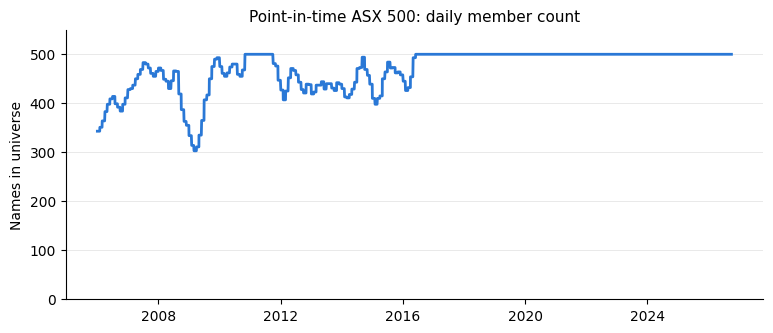

date,2006,2007,2008,2009,2010,2011,2012,2013,2014,2015,...,2017,2018,2019,2020,2021,2022,2023,2024,2025,2026
avg members,387.0,458.0,430.0,392.0,472.0,492.0,440.0,434.0,446.0,447.0,...,500.0,500.0,500.0,500.0,500.0,500.0,500.0,500.0,500.0,500.0


In [26]:
counts = member.sum(axis=1).loc["2006":]
fig, ax = plt.subplots(figsize=(9, 3.5))
ax.plot(counts.index, counts.values, color="#2a78d6", lw=2)
ax.set_ylim(0, 550)
ax.set_ylabel("Names in universe")
ax.set_title("Point-in-time ASX 500: daily member count", fontsize=11)
ax.spines[["top", "right"]].set_visible(False)
ax.grid(axis="y", color="#e5e5e5", lw=0.6)
plt.show()
counts.groupby(counts.index.year).mean().round(0).to_frame("avg members").T

Before 2017 the universe holds fewer than 500 names. Too few of *today's* listed companies existed and traded enough back then. This is the survivorship bias showing up directly.

## 5. Benchmarks and save

In [27]:
sector = meta.assign(ticker=meta["code"] + ".AX").set_index("ticker")["sector"]
bench = pd.read_parquet(DATA / "benchmarks.parquet")["adj_close"].unstack()
bench_ret = bench.pct_change(fill_method=None).reindex(adj.index)

d = dict(adj=adj, high=high, low=low, close=close, volume=vol, ret=ret, adv=adv,
         member=member, sector=sector.reindex(adj.columns), bench_ret=bench_ret)
pd.to_pickle(d, DATA / "clean.pkl")
{k: getattr(v, "shape", None) for k, v in d.items()}

{'adj': (5501, 1628),
 'high': (5501, 1628),
 'low': (5501, 1628),
 'close': (5501, 1628),
 'volume': (5501, 1628),
 'ret': (5501, 1628),
 'adv': (5501, 1628),
 'member': (5501, 1628),
 'sector': (1628,),
 'bench_ret': (5501, 2)}

| Key | Contents | Used for |
|---|---|---|
| `adj`, `high`, `low` | adjusted prices | breakout channels |
| `close` | raw prices | $0.10 rule, traded value |
| `volume`, `adv` | liquidity | universe, volume filter, capacity |
| `ret` | cleaned daily returns | P&L |
| `member` | True/False daily membership | the universe |
| `sector`, `bench_ret` | GICS group, ^AXJO / ^AORD returns | exposures, benchmarks |